In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display
students = ["Aarav", "Diya", "Kabir", "Ananya", "Vikram", "Ishita", "Rohan", "Meera",
            "Aditya", "Sana", "Yash", "Pooja", "Harsh", "Tanvi", "Nikhil", "Kavya",
            "Manav", "Riya", "Sahil", "Nisha", "Arjun", "Simran", "Dev", "Anjali",
            "Karan", "Priya", "Rahul", "Neha", "Sneha", "Amit"]

n = len(students)

study_hours = np.round(np.random.uniform(1, 9, n), 1)

attendance = np.clip(55 + 4.5 * study_hours + np.random.normal(0, 4, n), 50, 100).round().astype(int)

marks = np.clip(15 + 5.5 * study_hours + 0.25 * attendance + np.random.normal(0, 4, n), 30, 100).round().astype(int)

program = np.random.choice(["BCA", "BSc", "BCom", "BBA"], n)
assessment_date = pd.bdate_range("2026-02-02", periods=n)

df = pd.DataFrame({
    "Student": students,
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Marks": marks,
    "Program": program,
    "Assessment_Date": assessment_date
})

display(df)

,Student,Study_Hours,Attendance,Marks,Program,Assessment_Date
0,Aarav,5.2,81,70,BSc,2026-02-02
1,Diya,5.9,86,67,BBA,2026-02-03
2,Kabir,5.5,83,69,BCA,2026-02-04
3,Ananya,4.5,72,63,BCA,2026-02-05
4,Vikram,5.8,82,70,BCA,2026-02-06
5,Ishita,6.7,88,73,BSc,2026-02-09
6,Rohan,8.8,100,88,BCA,2026-02-10
7,Meera,1.7,65,43,BBA,2026-02-11
8,Aditya,2.2,56,35,BBA,2026-02-12
9,Sana,8.8,85,83,BSc,2026-02-13


In [ ]:
print("Dataset Shape (rows, columns):")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
display(df.describe())

print("\nProgram-wise Student Count:")
print(df["Program"].value_counts())

Dataset Shape (rows, columns):
(30, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Student          30 non-null     object        
 1   Study_Hours      30 non-null     float64       
 2   Attendance       30 non-null     int64         
 3   Marks            30 non-null     int64         
 4   Program          30 non-null     object        
 5   Assessment_Date  30 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(2), object(2)
memory usage: 1.5+ KB

Descriptive Statistics:


,Study_Hours,Attendance,Marks,Assessment_Date
count,30.000000,30.000000,30.000000,30
mean,4.576667,76.133333,59.033333,2026-02-21 12:00:00
min,1.300000,56.000000,34.000000,2026-02-02 00:00:00
25%,2.700000,70.500000,48.250000,2026-02-11 06:00:00
50%,4.800000,78.000000,60.500000,2026-02-21 12:00:00
75%,5.975000,83.000000,68.500000,2026-03-03 18:00:00
max,8.800000,100.000000,88.000000,2026-03-13 00:00:00
std,2.140687,10.766273,13.979007,NaN



Program-wise Student Count:
Program
BCA     9
BBA     8
BSc     7
BCom    6
Name: count, dtype: int64


Correlation Matrix:


,Study_Hours,Attendance,Marks
Study_Hours,1.000000,0.931810,0.937092
Attendance,0.931810,1.000000,0.924692
Marks,0.937092,0.924692,1.000000


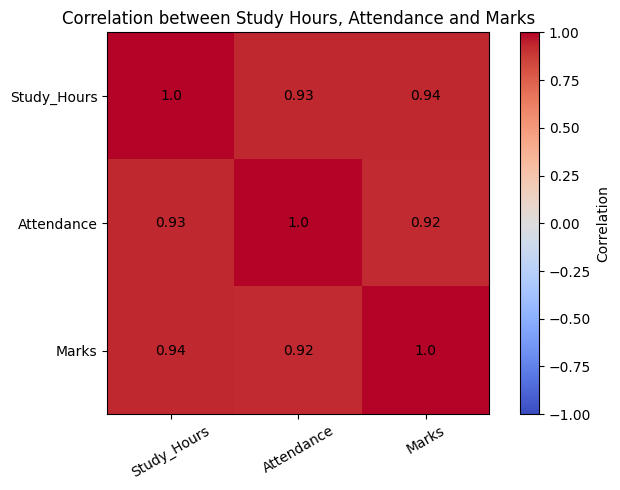

Correlation between Study Hours and Marks : 0.94
Correlation between Attendance and Marks  : 0.92
Interpretation: values close to +1 mean the two variables increase together. Correlation does not prove causation.


In [ ]:
correlation = df[["Study_Hours", "Attendance", "Marks"]].corr()
print("Correlation Matrix:")
display(correlation)

plt.figure(figsize=(7, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=30)
plt.yticks(range(len(correlation.columns)), correlation.columns)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, round(correlation.iloc[i, j], 2), ha="center", va="center")

plt.title("Correlation between Study Hours, Attendance and Marks")
plt.tight_layout()
plt.show()

r_study_marks = df["Study_Hours"].corr(df["Marks"])
r_att_marks = df["Attendance"].corr(df["Marks"])
print(f"Correlation between Study Hours and Marks : {r_study_marks:.2f}")
print(f"Correlation between Attendance and Marks  : {r_att_marks:.2f}")
print("Interpretation: values close to +1 mean the two variables increase together. Correlation does not prove causation.")


In [ ]:
program_summary = df.groupby("Program").agg(
    Average_Study_Hours=("Study_Hours", "mean"),
    Average_Attendance=("Attendance", "mean"),
    Average_Marks=("Marks", "mean"),
    Student_Count=("Student", "count")
).round(2).reset_index()

print("Program-wise Performance Summary:")
display(program_summary)

best_program = program_summary.loc[program_summary["Average_Marks"].idxmax(), "Program"]
best_avg = program_summary["Average_Marks"].max()
print(f"Highest average marks: {best_program} ({best_avg:.1f})")


Program-wise Performance Summary:


,Program,Average_Study_Hours,Average_Attendance,Average_Marks,Student_Count
0,BBA,3.54,72.12,52.00,8
1,BCA,4.98,78.33,60.89,9
2,BCom,4.53,75.50,59.67,6
3,BSc,5.29,78.43,64.14,7


Highest average marks: BSc (64.1)


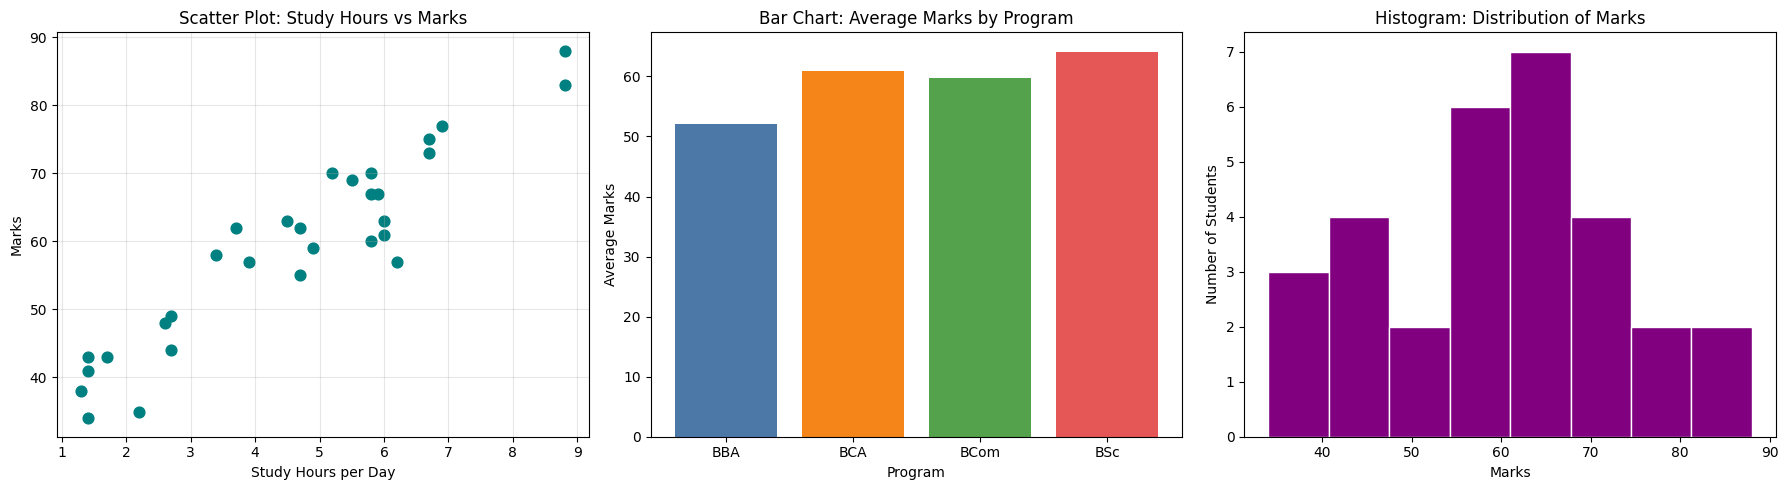

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(df["Study_Hours"], df["Marks"], color="teal", s=60)
axes[0].set_title("Scatter Plot: Study Hours vs Marks")
axes[0].set_xlabel("Study Hours per Day")
axes[0].set_ylabel("Marks")
axes[0].grid(alpha=0.3)

axes[1].bar(program_summary["Program"], program_summary["Average_Marks"],
            color=["#4C78A8", "#F58518", "#54A24B", "#E45756"])
axes[1].set_title("Bar Chart: Average Marks by Program")
axes[1].set_xlabel("Program")
axes[1].set_ylabel("Average Marks")

axes[2].hist(df["Marks"], bins=8, color="purple", edgecolor="white")
axes[2].set_title("Histogram: Distribution of Marks")
axes[2].set_xlabel("Marks")
axes[2].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [ ]:
fig1 = px.scatter(df, x="Study_Hours", y="Marks", color="Program",
                  size="Attendance", hover_name="Student",
                  title="Study Hours vs Marks (hover over a point for details)")
fig1.show()

fig2 = px.bar(program_summary, x="Program", y="Average_Marks", color="Program",
              text="Average_Marks", title="Average Marks by Program")
fig2.show()

fig3 = px.histogram(df, x="Marks", nbins=8, title="Distribution of Marks")
fig3.show()

fig4 = px.line(df.sort_values("Assessment_Date"), x="Assessment_Date", y="Marks",
               markers=True, hover_name="Student", title="Marks Across Assessment Dates")
fig4.show()


In [ ]:
slope, intercept = np.polyfit(df["Study_Hours"], df["Marks"], 1)
pct_pass = (df["Marks"] >= 60).mean() * 100
df_sorted = df.sort_values("Assessment_Date")
top_student = df.loc[df["Marks"].idxmax()]

title1 = f"Every extra study hour adds about {slope:.1f} marks (r = {r_study_marks:.2f})"
title2 = f"{best_program} students lead with an average of {best_avg:.1f} marks"
title3 = f"{pct_pass:.0f}% of students score 60 or above"
title4 = f"Highest score ({top_student['Marks']}) was by {top_student['Student']} on {top_student['Assessment_Date'].date()}"

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(title1, title2, title3, title4)
)

fig.add_trace(go.Scatter(
    x=df["Study_Hours"], y=df["Marks"], mode="markers", name="Students",
    text=df["Student"], marker=dict(size=10, color=df["Attendance"], colorscale="Viridis",
                                    showscale=True, colorbar=dict(title="Attendance %", x=0.45, len=0.4, y=0.8))
), row=1, col=1)
x_line = np.linspace(df["Study_Hours"].min(), df["Study_Hours"].max(), 50)
fig.add_trace(go.Scatter(x=x_line, y=slope * x_line + intercept, mode="lines",
                         name="Trend line", line=dict(color="red", dash="dash")), row=1, col=1)

fig.add_trace(go.Bar(x=program_summary["Program"], y=program_summary["Average_Marks"],
                     name="Average Marks", text=program_summary["Average_Marks"],
                     marker_color="#4C78A8"), row=1, col=2)


fig.add_trace(go.Histogram(x=df["Marks"], nbinsx=8, name="Marks Distribution",
                           marker_color="purple"), row=2, col=1)

fig.add_trace(go.Scatter(x=df_sorted["Assessment_Date"], y=df_sorted["Marks"],
                         mode="lines+markers", name="Marks over time", text=df_sorted["Student"],
                         line=dict(color="green")), row=2, col=2)

fig.update_xaxes(title_text="Study Hours per Day", row=1, col=1)
fig.update_yaxes(title_text="Marks", row=1, col=1)
fig.update_xaxes(title_text="Program", row=1, col=2)
fig.update_yaxes(title_text="Average Marks", row=1, col=2)
fig.update_xaxes(title_text="Marks", row=2, col=1)
fig.update_yaxes(title_text="Number of Students", row=2, col=1)
fig.update_xaxes(title_text="Assessment Date", row=2, col=2)
fig.update_yaxes(title_text="Marks", row=2, col=2)

fig.update_layout(
    title_text="Student Academic Performance Analytics Dashboard",
    height=800, template="plotly_white", showlegend=False
)
fig.show()

In [ ]:
fig.write_html("student_performance_dashboard.html")
print("Dashboard exported as student_performance_dashboard.html")

try:
    from google.colab import files
    files.download("student_performance_dashboard.html")
except ImportError:
    print("Not running in Colab - the HTML file is saved in the current folder.")


Dashboard exported as student_performance_dashboard.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
reflection = (
    f"This dashboard analysed the academic performance of {len(df)} students using study hours, "
    f"attendance, marks, program and assessment date. The strongest story is that effort pays off: "
    f"study hours and marks have a correlation of {r_study_marks:.2f}, and each additional daily study hour "
    f"is associated with roughly {slope:.1f} more marks. Attendance also moves with marks "
    f"(correlation {r_att_marks:.2f}), which suggests that students who attend regularly and study consistently "
    f"perform best. Among the programs, {best_program} students achieved the highest average marks "
    f"({best_avg:.1f}), and {pct_pass:.0f}% of all students scored 60 or above. The marks across "
    f"assessment dates do not follow a clear trend, so performance depends more on individual habits than on "
    f"the date of the assessment. Overall, the dashboard shows that colleges can improve results by encouraging "
    f"regular attendance and steady study routines, and by giving extra support to students who study fewer "
    f"hours. Since correlation does not prove causation, these insights should be treated as guidance and not as proof."
)

print("REFLECTION:\n")
print(reflection)

REFLECTION:

This dashboard analysed the academic performance of 30 students using study hours, attendance, marks, program and assessment date. The strongest story is that effort pays off: study hours and marks have a correlation of 0.94, and each additional daily study hour is associated with roughly 6.1 more marks. Attendance also moves with marks (correlation 0.92), which suggests that students who attend regularly and study consistently perform best. Among the programs, BSc students achieved the highest average marks (64.1), and 53% of all students scored 60 or above. The marks across assessment dates do not follow a clear trend, so performance depends more on individual habits than on the date of the assessment. Overall, the dashboard shows that colleges can improve results by encouraging regular attendance and steady study routines, and by giving extra support to students who study fewer hours. Since correlation does not prove causation, these insights should be treated as guidan

In [ ]:
df.to_csv("student_data.csv", index=False)